# DSC212 Research Assignment: Modularity on the Karate Club Graph

**Name:** Sachin Gautam

**Roll Number:** IMS25300  
**Course:** DSC212 — Graph Theory Module  

## Aim
Implement recursive spectral modularity partitioning on Zachary's Karate Club graph, visualize the communities after each split, calculate degree, betweenness, closeness and clustering metrics after each split, plot how these metrics evolve, and discuss the results.

## Method and conventions
- The graph is the unweighted, undirected Karate Club graph supplied by NetworkX.
- The global modularity matrix is \(B=A-\frac{kk^\top}{2m}\), and the assignment's modularity convention is \(Q=\frac{1}{4m}s^\top Bs\) for a two-way split.
- For each candidate community \(C\), this notebook follows the handout's specified restricted matrix \(B^{(C)}=B[C,C]\). The leading eigenvector is thresholded by sign; recursion stops when its largest eigenvalue is nonpositive.
- To make the requested metric evolution informative, metrics at each iteration are calculated on each node's **current community-induced subgraph**. Thus a node's local centrality/cohesion can change as its community is subdivided. This convention is stated explicitly because metrics calculated on the unchanged full graph would be identical at every iteration.
- The node positions are calculated once and reused in every community plot, so changes in colors show the splits rather than layout movement.



In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from IPython.display import display

SEED = 42
G = nx.karate_club_graph()
nodes = list(G.nodes())
n = G.number_of_nodes()
m = G.number_of_edges()

A = nx.to_numpy_array(G, nodelist=nodes, dtype=float)
k = A.sum(axis=1)
B = A - np.outer(k, k) / (2 * m)

print(f"Number of nodes: {n}")
print(f"Number of edges: {m}")
print(f"Global modularity matrix shape: {B.shape}")
print("Graph is undirected:", not G.is_directed())
print("Node IDs:", nodes)

Number of nodes: 34
Number of edges: 78
Global modularity matrix shape: (34, 34)
Graph is undirected: True
Node IDs: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33]


## 1. Inspect and visualize the original network

Node labels in the NetworkX dataset identify the 34 club members. The `club` attribute is the recorded faction label used only for reference; the spectral algorithm below uses the graph structure and does not use those labels to make its splits.

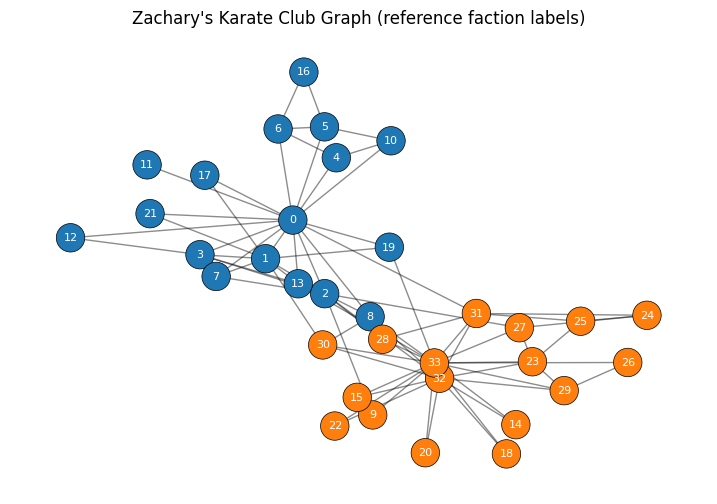

Reference faction sizes:


,Number of nodes
Faction,
Mr. Hi,17
Officer,17


In [ ]:
pos = nx.spring_layout(G, seed=SEED)
club_labels = nx.get_node_attributes(G, "club")
club_colors = ["tab:blue" if club_labels[v] == "Mr. Hi" else "tab:orange" for v in G.nodes()]

plt.figure(figsize=(9, 6))
nx.draw_networkx_edges(G, pos, alpha=0.45, width=1.0)
nx.draw_networkx_nodes(G, pos, node_color=club_colors, node_size=420, edgecolors="black", linewidths=0.5)
nx.draw_networkx_labels(G, pos, font_size=8, font_color="white")
plt.title("Zachary's Karate Club Graph (reference faction labels)")
plt.axis("off")
plt.show()

print("Reference faction sizes:")
display(pd.Series(club_labels).value_counts().rename_axis("Faction").to_frame("Number of nodes"))

## 2. Recursive spectral modularity algorithm

For a community \(C\), the algorithm extracts the block \(B^{(C)}=B[C,C]\), finds its largest eigenvalue and corresponding eigenvector, and splits the nodes according to the signs of the eigenvector entries if \(\lambda_{\max}>0\). The two resulting groups are processed recursively. A safety check stops if sign-thresholding produces an empty group, since an empty community is not a valid split.

In [ ]:
def restricted_modularity_matrix(community):
    """Return the assignment-defined block B[C, C] in the order of community."""
    idx = np.asarray(community, dtype=int)
    return B[np.ix_(idx, idx)]


def spectral_split(community, tolerance=1e-10):
    """Return (lambda_max, left_group, right_group), or no groups if unsplittable."""
    community = list(community)
    if len(community) < 2:
        return 0.0, None, None

    Bc = restricted_modularity_matrix(community)
    eigenvalues, eigenvectors = np.linalg.eigh(Bc)  # symmetric matrix
    lambda_max = float(eigenvalues[-1])
    leading_vector = eigenvectors[:, -1]

    if lambda_max <= tolerance:
        return lambda_max, None, None

    left = [node for node, value in zip(community, leading_vector) if value > 0]
    right = [node for node, value in zip(community, leading_vector) if value <= 0]

    # A valid split must have two nonempty groups.
    if not left or not right:
        return lambda_max, None, None
    return lambda_max, left, right


def current_communities(community_map):
    """Return current leaf communities ordered by their creation ID."""
    return [community_map[cid] for cid in sorted(community_map)]


def community_metrics(communities):
    """Compute node metrics on each node's current community-induced subgraph."""
    result = {
        metric: {node: np.nan for node in G.nodes()}
        for metric in ["Degree centrality", "Betweenness centrality",
                       "Closeness centrality", "Clustering coefficient"]
    }
    for community in communities:
        H = G.subgraph(community).copy()
        degree = nx.degree_centrality(H)
        between = nx.betweenness_centrality(H, normalized=True)
        close = nx.closeness_centrality(H)
        clustering = nx.clustering(H)
        for node in community:
            result["Degree centrality"][node] = degree[node]
            result["Betweenness centrality"][node] = between[node]
            result["Closeness centrality"][node] = close[node]
            result["Clustering coefficient"][node] = clustering[node]
    return result


# Each snapshot contains the leaf communities after a completed split.
community_map = {0: nodes.copy()}
next_community_id = 1
split_records = []
snapshots = [current_communities(community_map)]
metric_history = [community_metrics(snapshots[0])]
snapshot_labels = ["Initial"]

# Queue-based recursion: split the first splittable leaf; keep processing until none remain.
while True:
    did_split = False
    for cid in sorted(list(community_map)):
        community = community_map[cid]
        lambda_max, left, right = spectral_split(community)
        if left is not None and right is not None:
            del community_map[cid]
            left_id, right_id = next_community_id, next_community_id + 1
            next_community_id += 2
            community_map[left_id] = left
            community_map[right_id] = right
            split_records.append({
                "Split number": len(split_records) + 1,
                "Parent community size": len(community),
                "Largest eigenvalue": lambda_max,
                "Left size": len(left),
                "Right size": len(right),
                "Left nodes": sorted(left),
                "Right nodes": sorted(right),
            })
            communities_now = current_communities(community_map)
            snapshots.append(communities_now)
            metric_history.append(community_metrics(communities_now))
            snapshot_labels.append(f"After split {len(split_records)}")
            did_split = True
            break
    if not did_split:
        break

split_table = pd.DataFrame(split_records)
print(f"Number of accepted splits: {len(split_records)}")
print(f"Final number of communities: {len(current_communities(community_map))}")
display(split_table if not split_table.empty else pd.DataFrame({"Result": ["No positive-eigenvalue split was accepted."]}))

Number of accepted splits: 12
Final number of communities: 13


,Split number,Parent community size,Largest eigenvalue,Left size,Right size,Left nodes,Right nodes
0,1,34,17.108349,18,16,"[8, 9, 14, 15, 18, 20, 22, 23, 24, 25, 26, 27,...","[0, 1, 2, 3, 4, 5, 6, 7, 10, 11, 12, 13, 16, 1..."
1,2,18,7.879863,12,6,"[8, 9, 14, 15, 18, 20, 22, 26, 29, 30, 32, 33]","[23, 24, 25, 27, 28, 31]"
2,3,16,9.851071,8,8,"[1, 2, 3, 7, 12, 13, 19, 21]","[0, 4, 5, 6, 10, 11, 16, 17]"
3,4,12,3.789452,2,10,"[26, 29]","[8, 9, 14, 15, 18, 20, 22, 30, 32, 33]"
4,5,6,4.224803,4,2,"[24, 25, 28, 31]","[23, 27]"
5,6,8,2.112386,4,4,"[1, 2, 19, 21]","[3, 7, 12, 13]"
6,7,8,5.457362,3,5,"[0, 11, 17]","[4, 5, 6, 10, 16]"
7,8,10,1.883391,8,2,"[9, 14, 15, 18, 20, 22, 32, 33]","[8, 30]"
8,9,4,0.463469,1,3,[2],"[1, 19, 21]"
9,10,4,1.765911,3,1,"[3, 7, 12]",[13]


## 3. Visualize the communities after every split

The same spring-layout coordinates are used for all panels. Each current community has a distinct color and every node is labelled by its ID.

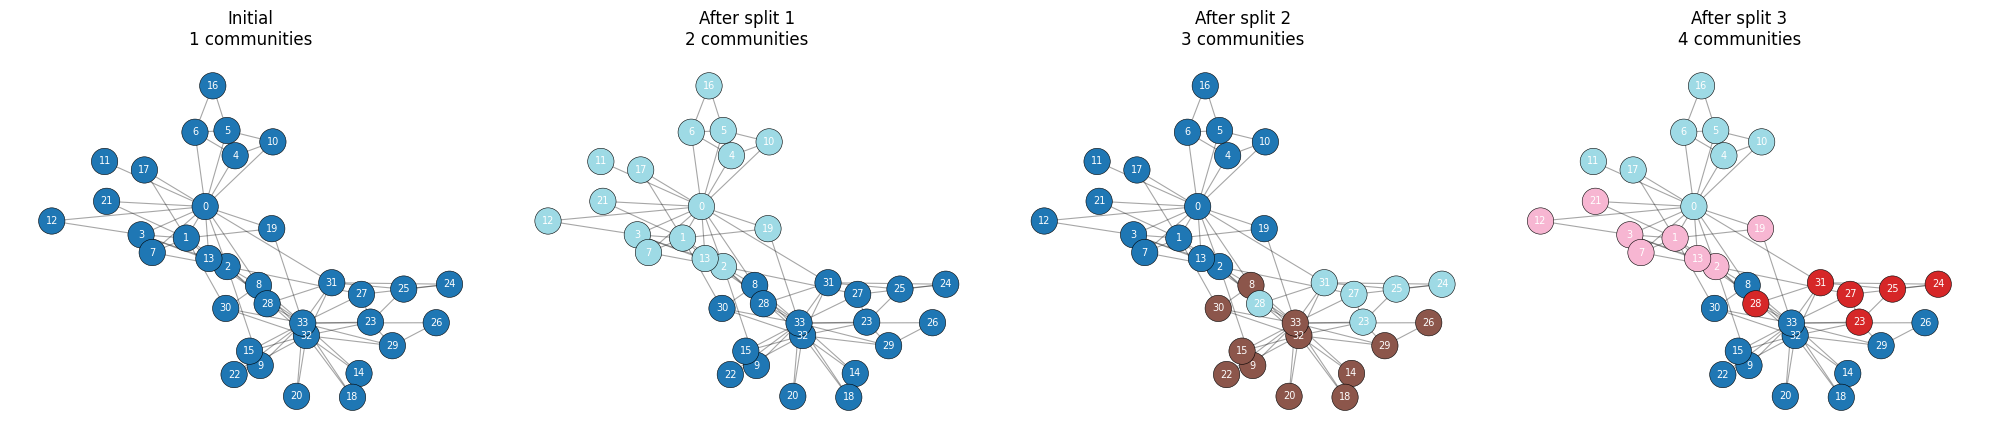

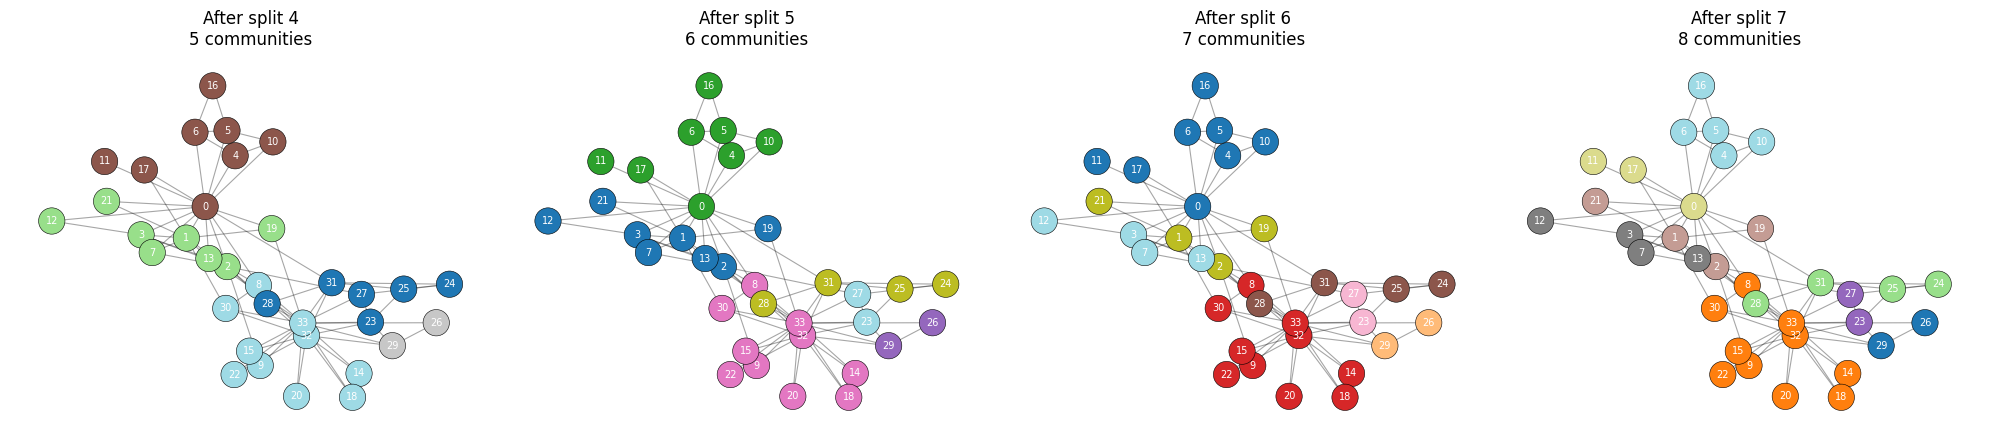

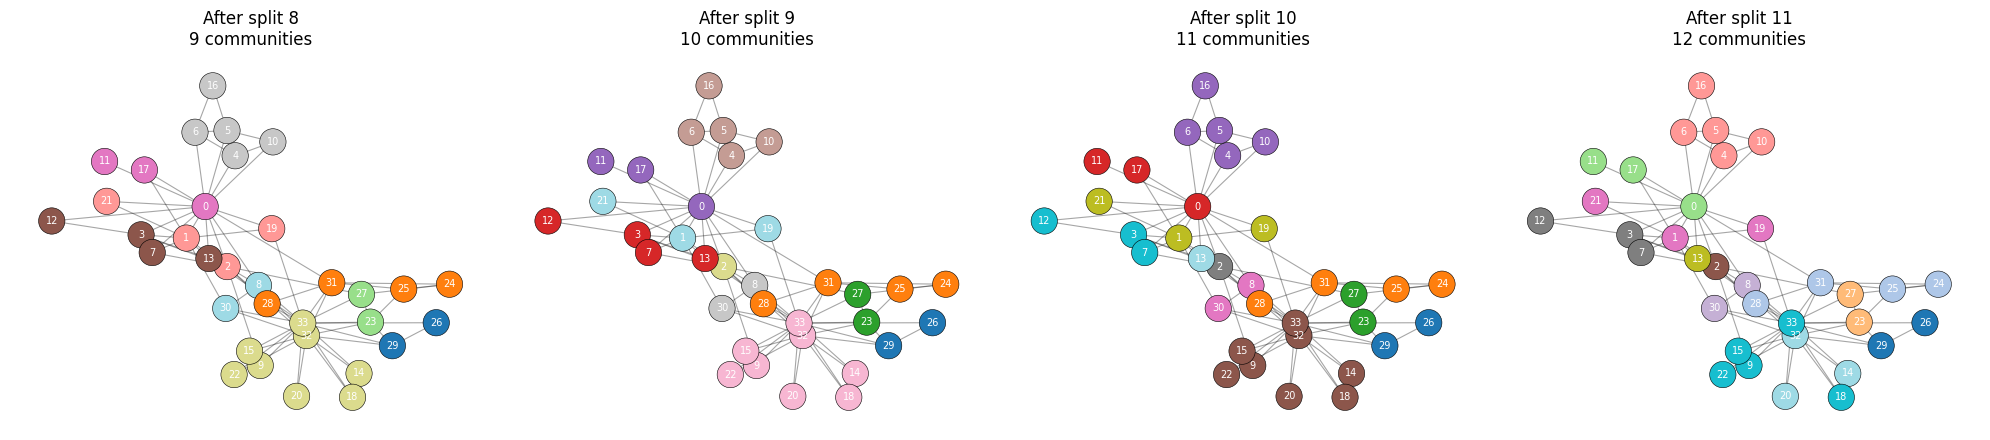

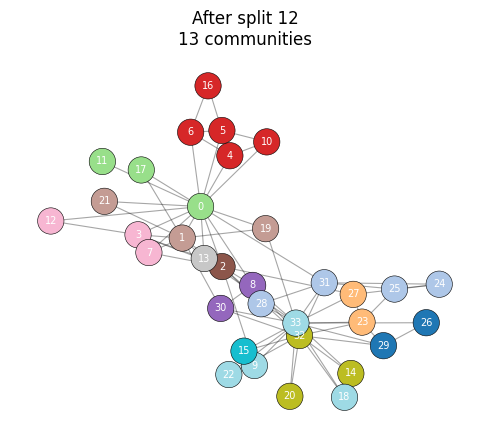

Community sizes after each split:
Initial: [34]
After split 1: [18, 16]
After split 2: [16, 12, 6]
After split 3: [12, 6, 8, 8]
After split 4: [6, 8, 8, 2, 10]
After split 5: [8, 8, 2, 10, 4, 2]
After split 6: [8, 2, 10, 4, 2, 4, 4]
After split 7: [2, 10, 4, 2, 4, 4, 3, 5]
After split 8: [2, 4, 2, 4, 4, 3, 5, 8, 2]
After split 9: [2, 4, 2, 4, 3, 5, 8, 2, 1, 3]
After split 10: [2, 4, 2, 3, 5, 8, 2, 1, 3, 3, 1]
After split 11: [2, 4, 2, 3, 5, 2, 1, 3, 3, 1, 5, 3]
After split 12: [2, 4, 2, 3, 5, 2, 1, 3, 3, 1, 3, 1, 4]


In [ ]:
def draw_partition(communities, title, ax):
    palette = plt.get_cmap("tab20", max(len(communities), 1))
    color_by_node = {}
    for idx, community in enumerate(communities):
        for node in community:
            color_by_node[node] = palette(idx)
    nx.draw_networkx_edges(G, pos, ax=ax, alpha=0.35, width=0.8)
    nx.draw_networkx_nodes(
        G, pos, nodelist=nodes,
        node_color=[color_by_node[v] for v in nodes],
        node_size=360, edgecolors="black", linewidths=0.4, ax=ax
    )
    nx.draw_networkx_labels(G, pos, font_size=7, font_color="white", ax=ax)
    ax.set_title(f"{title}\n{len(communities)} communities")
    ax.axis("off")

for start in range(0, len(snapshots), 4):
    subset = list(range(start, min(start + 4, len(snapshots))))
    fig, axes = plt.subplots(1, len(subset), figsize=(5 * len(subset), 4.5))
    if len(subset) == 1:
        axes = [axes]
    for ax, idx in zip(axes, subset):
        draw_partition(snapshots[idx], snapshot_labels[idx], ax)
    plt.tight_layout()
    plt.show()

print("Community sizes after each split:")
for label, communities in zip(snapshot_labels, snapshots):
    print(f"{label}: {[len(c) for c in communities]}")

## 4. Centrality and cohesion metrics after each split

The following metrics are computed with NetworkX at each snapshot, on each node's current community-induced subgraph:

1. **Degree centrality:** fraction of other nodes in the same community directly connected to the node.
2. **Betweenness centrality:** fraction of shortest paths within that subgraph that pass through the node.
3. **Closeness centrality:** based on the node's shortest-path distances to other nodes in that subgraph.
4. **Clustering coefficient:** fraction of pairs of a node's neighbors that are connected.

A node that is alone in a community receives zero for these metrics under NetworkX's conventions. Since the analysis uses community-induced subgraphs, these are *within-community* metrics, not recomputations of the unchanged full-graph metrics.

In [ ]:
metric_names = [
    "Degree centrality",
    "Betweenness centrality",
    "Closeness centrality",
    "Clustering coefficient",
]

# Long-form table: one row per iteration, node and metric.
metric_rows = []
for iteration, (label, metric_dict) in enumerate(zip(snapshot_labels, metric_history)):
    for metric_name in metric_names:
        for node in nodes:
            metric_rows.append({
                "Iteration": iteration,
                "Snapshot": label,
                "Node": node,
                "Metric": metric_name,
                "Value": metric_dict[metric_name][node],
            })
metrics_df = pd.DataFrame(metric_rows)

print("First rows of the metric table:")
display(metrics_df.head(12))
print(f"Metric observations stored: {len(metrics_df)}")

First rows of the metric table:


,Iteration,Snapshot,Node,Metric,Value
0,0,Initial,0,Degree centrality,0.484848
1,0,Initial,1,Degree centrality,0.272727
2,0,Initial,2,Degree centrality,0.303030
3,0,Initial,3,Degree centrality,0.181818
4,0,Initial,4,Degree centrality,0.090909
5,0,Initial,5,Degree centrality,0.121212
6,0,Initial,6,Degree centrality,0.121212
7,0,Initial,7,Degree centrality,0.121212
8,0,Initial,8,Degree centrality,0.151515
9,0,Initial,9,Degree centrality,0.060606


Metric observations stored: 1768


## 5. Plot the evolution of every metric for every node

Each plot has one line per node, with the x-axis showing the initial graph and each accepted split. Node IDs are consistent across all plots.

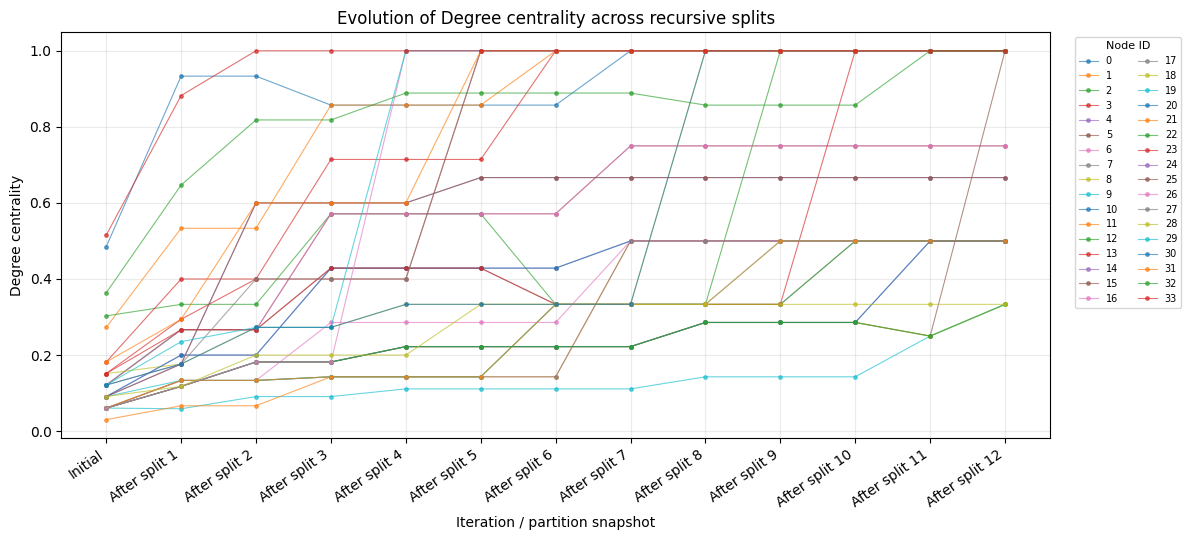

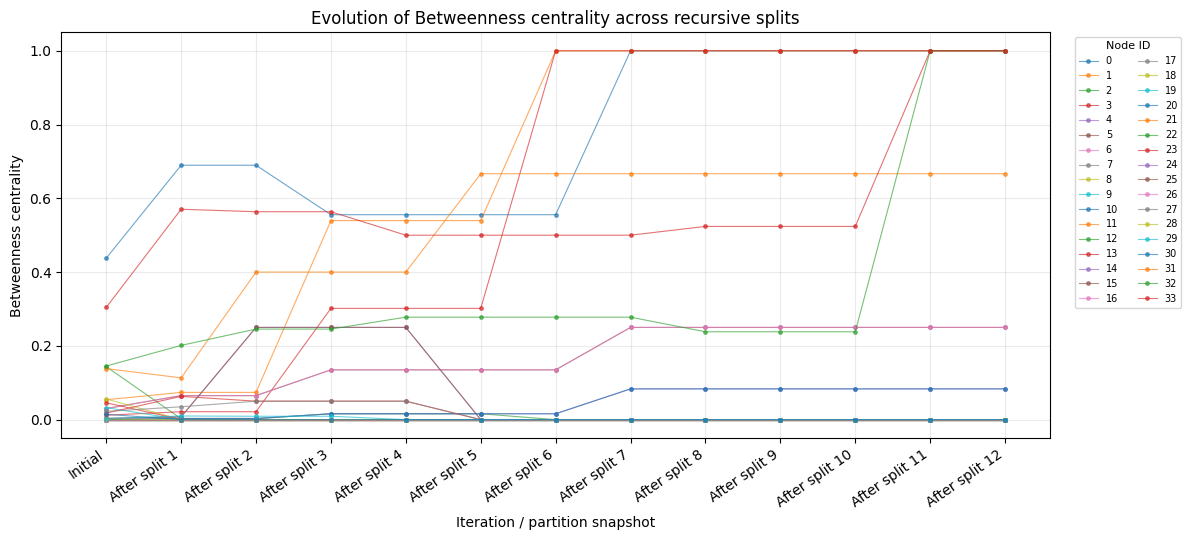

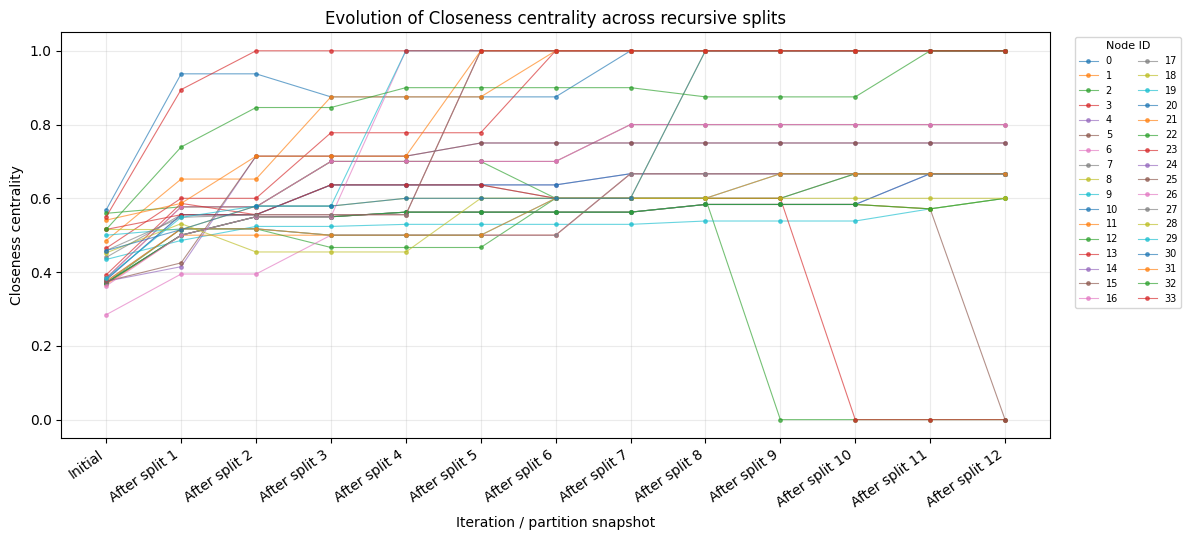

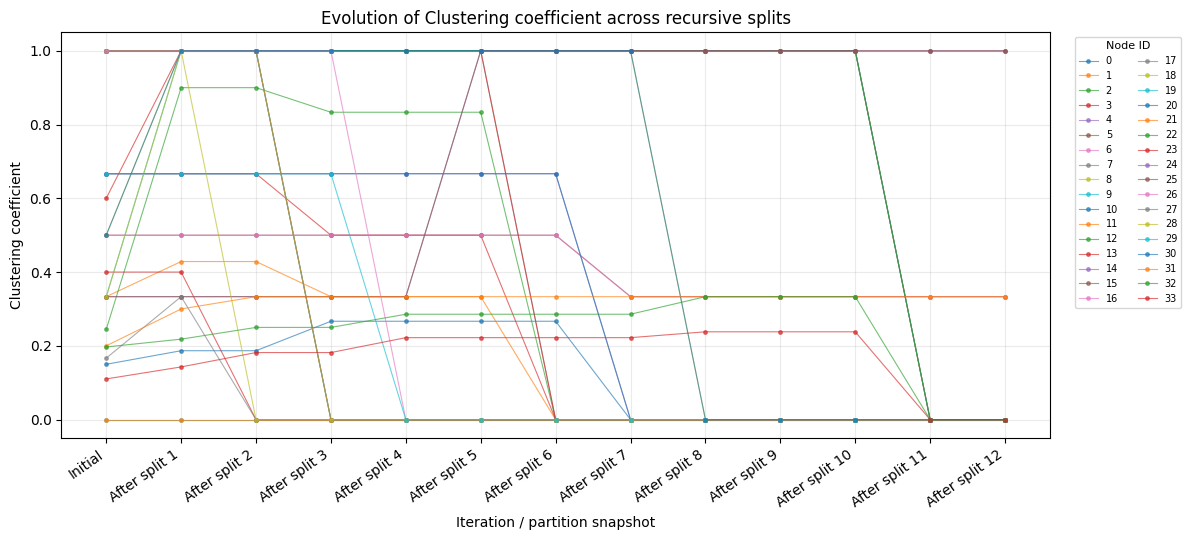

In [ ]:
for metric_name in metric_names:
    plt.figure(figsize=(12, 5.5))
    for node in nodes:
        values = [
            metric_history[i][metric_name][node]
            for i in range(len(metric_history))
        ]
        plt.plot(range(len(values)), values, marker="o", markersize=2.5,
                 linewidth=0.8, alpha=0.65, label=str(node))
    plt.xticks(range(len(snapshot_labels)), snapshot_labels, rotation=35, ha="right")
    plt.xlabel("Iteration / partition snapshot")
    plt.ylabel(metric_name)
    plt.title(f"Evolution of {metric_name} across recursive splits")
    plt.grid(True, alpha=0.25)
    plt.legend(title="Node ID", bbox_to_anchor=(1.02, 1), loc="upper left",
               ncol=2, fontsize=7, title_fontsize=8)
    plt.tight_layout()
    plt.show()

## 6. Identify nodes that remain central

To make the discussion evidence-based, calculate the average rank of each node for degree, betweenness and closeness across all snapshots. Rank 1 means the highest value in that snapshot. This is a compact indicator of nodes that repeatedly occupy central positions within their current communities.

In [ ]:
centrality_metrics = [
    "Degree centrality", "Betweenness centrality", "Closeness centrality"
]
rank_rows = []
for iteration, metric_dict in enumerate(metric_history):
    for metric_name in centrality_metrics:
        series = pd.Series(metric_dict[metric_name], dtype=float)
        ranks = series.rank(ascending=False, method="average")
        for node in nodes:
            rank_rows.append({
                "Iteration": iteration,
                "Metric": metric_name,
                "Node": node,
                "Rank": ranks[node],
                "Value": series[node],
            })
ranks_df = pd.DataFrame(rank_rows)
mean_ranks = (
    ranks_df.groupby(["Node", "Metric"])["Rank"].mean()
    .unstack("Metric")
)
mean_ranks["Mean rank across three metrics"] = mean_ranks[centrality_metrics].mean(axis=1)
top_central_nodes = mean_ranks.sort_values("Mean rank across three metrics").head(8)
display(top_central_nodes.round(3))

print("Nodes with the highest degree in the original graph:")
original_degree = pd.Series(dict(G.degree()), name="Degree").sort_values(ascending=False)
display(original_degree.head(8).to_frame())

Metric,Betweenness centrality,Closeness centrality,Degree centrality,Mean rank across three metrics
Node,,,,
33,3.462,4.077,4.231,3.923
0,2.000,5.115,5.500,4.205
1,3.269,5.923,5.923,5.038
31,4.000,5.808,6.385,5.397
3,5.192,6.577,6.692,6.154
32,5.692,7.308,7.500,6.833
5,7.769,12.962,13.615,11.449
6,7.846,12.962,13.615,11.474


Nodes with the highest degree in the original graph:


,Degree
33,17
0,16
32,12
2,10
1,9
3,6
31,6
23,5


## 7. Discussion and conclusion

### Discussion guide (complete using the outputs above)
- **Nodes that remain central:** Use the table of average ranks and the original-degree table. In this dataset, nodes **0, 33, 32, 2 and 1** are among the highest-degree nodes in the original network; nodes **0 and 33** are especially prominent in many standard analyses of this graph. Check whether the within-community metric plots preserve or change that ranking after the splits.
- **Effect of community structure:** As a community is subdivided, a node loses access to neighbors and shortest paths that lie outside its current community-induced subgraph. Its within-community degree and closeness can therefore fall; betweenness may rise or fall depending on whether it still bridges paths inside its community; clustering can rise when the remaining neighbors are tightly connected or fall when a split separates them.
- **Important distinction:** The graph's original edges do not change. These metric changes arise from restricting calculations to the current communities, not from rewiring or deleting edges from the original graph.
- **Limitations:** The spectral method uses an eigenvector relaxation and sign thresholding, so it does not guarantee the globally optimal discrete partition. The recursive result can depend on eigenvector signs in degenerate cases and on the precise restricted-matrix convention. The implementation follows the handout's stated block \(B[C,C]\) and positive-eigenvalue stopping rule.

### Conclusion
This notebook implements recursive spectral partitioning using the leading eigenvector of the restricted modularity matrix, visualizes each accepted split, and records and plots four NetworkX metrics after every split. The tables and plots provide evidence for discussing how nodes' roles change as the network is divided into smaller communities.

### Reference
Newman, M. E. J. (2006). “Modularity and community structure in networks.” *Proceedings of the National Academy of Sciences*, 103(23), 8577–8582. https://doi.org/10.1073/pnas.0601602103
